In [7]:
# ---------------------------------------------------------------------------
# 0. Import Libraries and Reproducibility setup
# ---------------------------------------------------------------------------
import os
import sys
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize


SEED = 42                                                 # Random seed 
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------------------
X = np.load('..\Function_2_Data\Week_8_Data/F2_Week_8_inputs.npy')
y = np.load('..\Function_2_Data\Week_8_Data/F2_Week_8_outputs.npy')
n, d = X.shape
print(f"n_samples={n}, n_dims={d}")


n_samples=17, n_dims=2


In [9]:
# ---------------------------------------------------------------------------
# 2. Data transformation
# ---------------------------------------------------------------------------
# INPUTS: already confined to [0, 1] x [0, 1]. 
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])

# OUTPUTS: standardize (zero mean, unit variance). 
y_mean, y_std = y.mean(), y.std()
y_scaled = (y - y_mean) / y_std

def unscale_y(y_s):
    return y_s * y_std + y_mean      #  Map standardized y back to original units.

In [10]:
# ---------------------------------------------------------------------------
# 3. Surrogate model: Gaussian Process Regression - Matern(nu=2.5) with WhiteKernel
# ---------------------------------------------------------------------------
kernel = (
    ConstantKernel(1.0, constant_value_bounds=(1e-3, 1e3))     
    * Matern(length_scale=[0.3, 0.3], 
             length_scale_bounds=(1e-2, 2.0),
             nu=2.5)
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e-1)) 
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=20,   # multiple restarts -> robust to local optima in ARD fitting
    normalize_y=False,         # we already standardized y ourselves
    random_state=SEED,
)
gp.fit(X, y_scaled)

print("\nFitted kernel:", gp.kernel_)
print("Log-marginal-likelihood:", gp.log_marginal_likelihood_value_)


Fitted kernel: 0.995**2 * Matern(length_scale=[0.0624, 2], nu=2.5) + WhiteKernel(noise_level=0.0488)
Log-marginal-likelihood: -14.942524120786057


C:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [11]:
# ---------------------------------------------------------------------------
# 4. Acquisition function: Expected Improvement (EI)
# ---------------------------------------------------------------------------

XI = 0.01

def expected_improvement(X_cand, gp, y_best, xi=XI):
    """
    Vectorized EI for maximization.
    X_cand: (m, d) candidate points
    y_best: best observed value so far (standardized scale)
    """
    mu, sigma = gp.predict(X_cand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)  # avoid division by zero
    imp = mu - y_best - xi
    z = imp / sigma
    ei = imp * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

y_best = y_scaled.max()
best_idx = np.argmax(y_scaled)
print(f"\nBest observed point so far: x={X[best_idx]}, y={y[best_idx]:.4f}")


Best observed point so far: x=[0.70556 0.     ], y=0.6528


In [12]:
# ---------------------------------------------------------------------------
# 5. Optimize the acquisition function (multi-start L-BFGS-B)
# ---------------------------------------------------------------------------

N_RESTARTS = 50

def neg_ei(x):
    return -expected_improvement(x.reshape(1, -1), gp, y_best)[0]

best_x, best_val = None, np.inf
starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(N_RESTARTS, d))
for x0 in starts:
    res = minimize(neg_ei, x0, bounds=bounds, method="L-BFGS-B")
    if res.fun < best_val:
        best_val, best_x = res.fun, res.x

print(f"\nNext suggested query point: x = {best_x}")
print(f"Expected Improvement at that point: {-best_val:.6f} (standardized y units)")


Next suggested query point: x = [0.70488097 0.        ]
Expected Improvement at that point: 0.078352 (standardized y units)


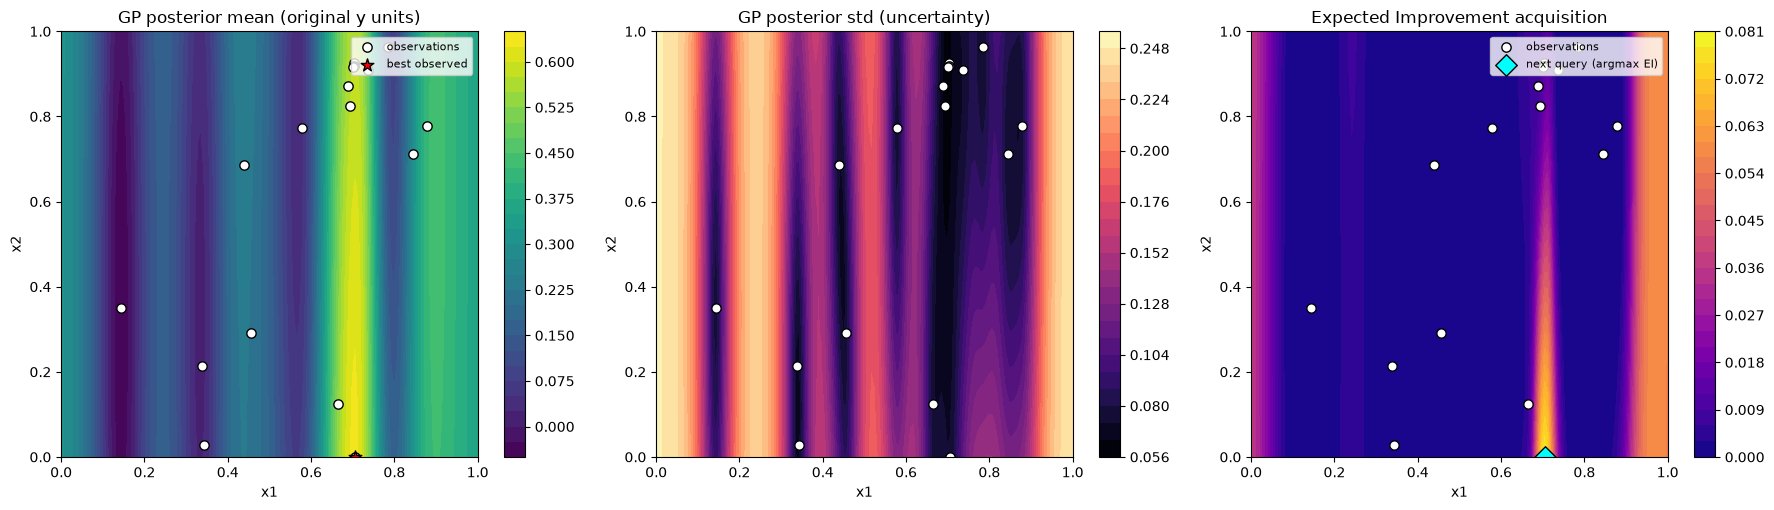

In [13]:
# ---------------------------------------------------------------------------
# 6. Plots
# ---------------------------------------------------------------------------
grid_n = 150
gx = np.linspace(0, 1, grid_n)
gy = np.linspace(0, 1, grid_n)
GX, GY = np.meshgrid(gx, gy)
grid_pts = np.column_stack([GX.ravel(), GY.ravel()])

mu_grid, std_grid = gp.predict(grid_pts, return_std=True)
mu_grid_orig = unscale_y(mu_grid).reshape(grid_n, grid_n)      # back to original y units
std_grid_orig = (std_grid * y_std).reshape(grid_n, grid_n)     # std scales linearly
ei_grid = expected_improvement(grid_pts, gp, y_best).reshape(grid_n, grid_n)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# (a) Posterior mean
im0 = axes[0].contourf(GX, GY, mu_grid_orig, levels=30, cmap="viridis")
axes[0].scatter(X[:, 0], X[:, 1], c="white", edgecolor="black", s=45, label="observations")
axes[0].scatter(*X[best_idx], c="red", edgecolor="black", s=90, marker="*", label="best observed")
axes[0].set_title("GP posterior mean (original y units)")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
fig.colorbar(im0, ax=axes[0])
axes[0].legend(loc="upper right", fontsize=8)

# (b) Posterior std (uncertainty)
im1 = axes[1].contourf(GX, GY, std_grid_orig, levels=30, cmap="magma")
axes[1].scatter(X[:, 0], X[:, 1], c="white", edgecolor="black", s=45)
axes[1].set_title("GP posterior std (uncertainty)")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2")
fig.colorbar(im1, ax=axes[1])

# (c) Expected Improvement + next point
im2 = axes[2].contourf(GX, GY, ei_grid, levels=30, cmap="plasma")
axes[2].scatter(X[:, 0], X[:, 1], c="white", edgecolor="black", s=45, label="observations")
axes[2].scatter(*best_x, c="cyan", edgecolor="black", s=120, marker="D", label="next query (argmax EI)")
axes[2].set_title("Expected Improvement acquisition")
axes[2].set_xlabel("x1"); axes[2].set_ylabel("x2")
fig.colorbar(im2, ax=axes[2])
axes[2].legend(loc="upper right", fontsize=8)
plt.tight_layout()